In [7]:
from random import random, shuffle, choice, randint, seed
import matplotlib.pyplot as plt

N = 30
C = 10

seed(42)
children = tuple(
    tuple(choice([True, False]) for j in range(C))
    for i in range(N)
)
children

((True, True, False, True, True, True, True, True, False, True),
 (True, True, True, True, True, True, False, True, False, False),
 (True, True, False, False, False, True, True, False, True, True),
 (False, True, False, False, False, True, False, True, False, True),
 (False, False, True, True, True, True, False, True, True, True),
 (False, False, False, False, True, False, False, True, False, True),
 (True, True, True, False, False, False, True, False, True, True),
 (True, False, False, False, True, True, False, True, False, False),
 (False, True, False, True, True, False, False, False, False, True),
 (True, False, True, True, True, True, True, False, True, False),
 (False, False, False, True, True, False, False, True, False, False),
 (True, False, True, False, True, True, False, True, True, False),
 (True, True, False, False, True, True, False, False, True, True),
 (True, True, True, False, True, True, True, False, True, False),
 (False, True, True, False, False, False, False, False, 

In [8]:
def fitness(children: tuple[tuple[bool]], sol: list[int]) -> int:
    sum = 0
    prev_pos = sol[-1]
    for pos in sol:
        child = children[pos]
        prev_child = children[prev_pos]
        for char1, char2 in zip(child, prev_child):
            if char1 != char2:
                sum += 1
        prev_pos = pos

    return sum

def tweak(sol: list[int]) -> list[int]:
    n = len(sol)
    new_sol = sol[:]
    n_swaps = randint(1, n)

    while random() > 0.8:
    #for _ in range(n_swaps):
        pos1 = randint(0, n - 1)
        pos2 = randint(0, n - 1)

        aus = new_sol[pos1]
        new_sol[pos1] = new_sol[pos2]
        new_sol[pos2] = aus

    return new_sol

In [12]:
cur_sol = list(range(N))
shuffle(cur_sol)
cur_fitness = fitness(children, cur_sol)
iterations = 0
since_last_change = 0

best_fitnesses = [ cur_fitness ]
current_fitnesses = [ cur_fitness ]

print("0) New candidate:", cur_sol, "- score:", cur_fitness)
while since_last_change < 20_000:
    new_sol = tweak(cur_sol)
    new_fitness = fitness(children, new_sol)
    since_last_change += 1
    iterations +=1

    current_fitnesses.append(new_fitness)

    if new_fitness > cur_fitness:
        cur_sol = new_sol
        cur_fitness = new_fitness
        since_last_change = 0

        print(f"{iterations})", "New candidate:", cur_sol, "- score:", cur_fitness)

    best_fitnesses.append(cur_fitness)

0) New candidate: [15, 3, 7, 17, 25, 23, 19, 8, 13, 9, 26, 29, 22, 24, 5, 21, 12, 6, 18, 14, 1, 27, 20, 28, 4, 10, 16, 0, 11, 2] - score: 138
7) New candidate: [15, 3, 7, 17, 25, 23, 9, 8, 13, 19, 26, 29, 22, 24, 5, 21, 12, 6, 18, 14, 1, 27, 20, 28, 4, 10, 16, 0, 11, 2] - score: 140
32) New candidate: [15, 8, 7, 17, 25, 23, 9, 3, 13, 19, 26, 29, 22, 20, 5, 21, 12, 6, 18, 14, 1, 27, 24, 28, 4, 10, 16, 0, 11, 2] - score: 142
36) New candidate: [15, 8, 7, 17, 27, 23, 9, 3, 13, 19, 26, 29, 22, 20, 5, 21, 12, 6, 18, 14, 1, 25, 24, 28, 4, 10, 16, 0, 11, 2] - score: 144
64) New candidate: [15, 8, 23, 17, 27, 7, 9, 3, 13, 19, 26, 29, 22, 20, 5, 21, 12, 6, 18, 14, 1, 25, 24, 28, 4, 10, 16, 0, 11, 2] - score: 148
70) New candidate: [15, 8, 23, 16, 27, 7, 9, 3, 13, 19, 26, 29, 22, 20, 5, 21, 12, 6, 18, 14, 1, 25, 24, 28, 4, 10, 17, 0, 11, 2] - score: 150
92) New candidate: [15, 8, 23, 16, 27, 7, 9, 3, 13, 10, 26, 29, 6, 20, 5, 21, 12, 22, 18, 14, 1, 25, 24, 28, 4, 19, 17, 0, 11, 2] - score: 158
9

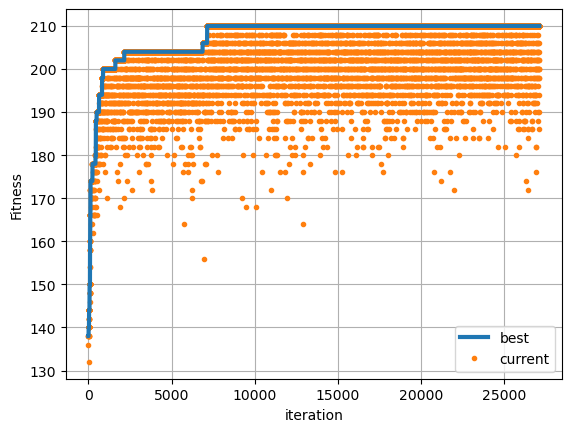

In [13]:
x = range(len(best_fitnesses))

plt.plot(x, best_fitnesses, '-', linewidth=3, zorder=3, label="best")
plt.plot(x, current_fitnesses, linestyle='None', marker='o', markersize=3, zorder=2, label="current")

plt.xlabel("iteration")
plt.ylabel("Fitness")
plt.legend()
plt.grid(True)
plt.show()